#DETECCIÓN VISUAL Y ESTADÍSTICA DE OUTLIERS (Boxplot, IQR y Z-Score)

▸ Ejercicio 1.1: Carga del Dataset e Inspección Visual con Boxplot (seaborn y matplotlib)

,id_cliente,edad,ingreso_mensual,tiempo_sesion_min
count,20.00,20.00,20.00,20.00
mean,210.50,35.25,2219.50,30.02
std,5.92,21.50,2930.17,49.73
min,201.00,24.00,1190.00,2.00
25%,205.75,27.75,1332.50,17.00
50%,210.50,30.50,1445.00,19.75
75%,215.25,34.25,1797.50,22.62
max,220.00,125.00,14500.00,240.00


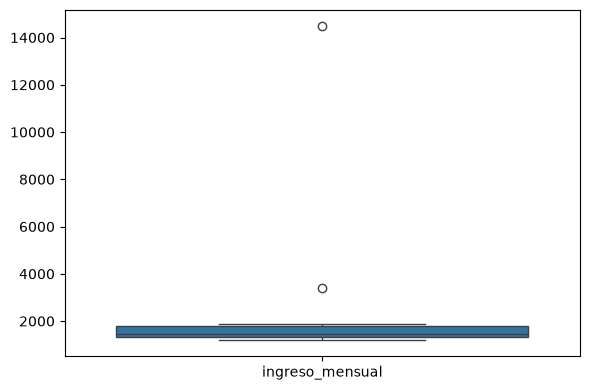

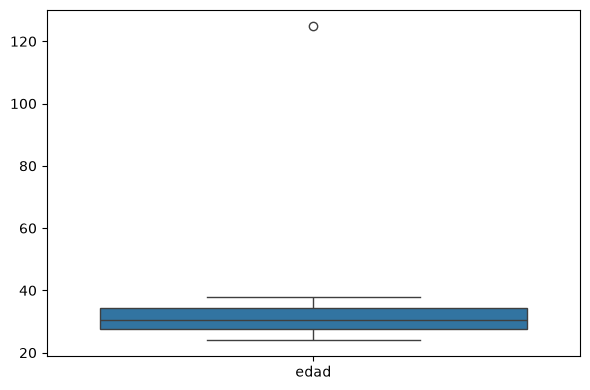

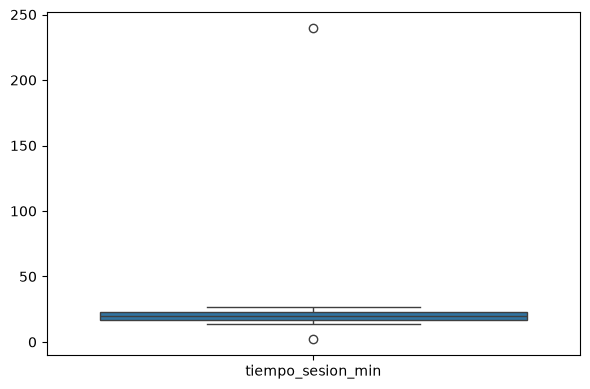

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\adria\Desktop\00_fapd_total\00_fapd\00_DATA_Clase03_Archivos_Actividades\DATA_Clientes_Outliers.csv")

display(df.describe().round(2))

plt.figure(figsize=(6, 4))
sns.boxplot(data=df[["ingreso_mensual"]])
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(data=df[["edad"]])
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(data=df[["tiempo_sesion_min"]])
plt.tight_layout()
plt.show()

▸ Ejercicio 1.2: Detección Numérica Robusta mediante Rango Intercuartílico (IQR)


In [2]:
Q1_ing = df["ingreso_mensual"].quantile(0.25)
Q3_ing = df["ingreso_mensual"].quantile(0.75)
IQR_ing = Q3_ing - Q1_ing
Li_ing = Q1_ing - 1.5 * IQR_ing
Ls_ing = Q3_ing + 1.5 * IQR_ing
atipicos_ing = df[(df["ingreso_mensual"] < Li_ing) | (df["ingreso_mensual"] > Ls_ing)]
print(f"ingreso_mensual: Q1={Q1_ing:.2f}, Q3={Q3_ing:.2f}, IQR={IQR_ing:.2f}, Li={Li_ing:.2f}, Ls={Ls_ing:.2f}")
print("Índices atípicos:", atipicos_ing.index.tolist())
display(atipicos_ing)

Q1_edad = df["edad"].quantile(0.25)
Q3_edad = df["edad"].quantile(0.75)
IQR_edad = Q3_edad - Q1_edad
Li_edad = Q1_edad - 1.5 * IQR_edad
Ls_edad = Q3_edad + 1.5 * IQR_edad
atipicos_edad = df[(df["edad"] < Li_edad) | (df["edad"] > Ls_edad)]
print(f"edad: Q1={Q1_edad:.2f}, Q3={Q3_edad:.2f}, IQR={IQR_edad:.2f}, Li={Li_edad:.2f}, Ls={Ls_edad:.2f}")
print("Índices atípicos:", atipicos_edad.index.tolist())
display(atipicos_edad)

Q1_tiempo = df["tiempo_sesion_min"].quantile(0.25)
Q3_tiempo = df["tiempo_sesion_min"].quantile(0.75)
IQR_tiempo = Q3_tiempo - Q1_tiempo
Li_tiempo = Q1_tiempo - 1.5 * IQR_tiempo
Ls_tiempo = Q3_tiempo + 1.5 * IQR_tiempo
atipicos_tiempo = df[(df["tiempo_sesion_min"] < Li_tiempo) | (df["tiempo_sesion_min"] > Ls_tiempo)]
print(f"tiempo_sesion_min: Q1={Q1_tiempo:.2f}, Q3={Q3_tiempo:.2f}, IQR={IQR_tiempo:.2f}, Li={Li_tiempo:.2f}, Ls={Ls_tiempo:.2f}")
print("Índices atípicos:", atipicos_tiempo.index.tolist())
display(atipicos_tiempo)

ingreso_mensual: Q1=1332.50, Q3=1797.50, IQR=465.00, Li=635.00, Ls=2495.00
Índices atípicos: [5, 14]


,id_cliente,segmento,edad,ingreso_mensual,tiempo_sesion_min
5,206,Estándar,125,14500,22.0
14,215,Premium,38,3400,27.0


edad: Q1=27.75, Q3=34.25, IQR=6.50, Li=18.00, Ls=44.00
Índices atípicos: [5]


,id_cliente,segmento,edad,ingreso_mensual,tiempo_sesion_min
5,206,Estándar,125,14500,22.0


tiempo_sesion_min: Q1=17.00, Q3=22.62, IQR=5.62, Li=8.56, Ls=31.06
Índices atípicos: [9, 11]


,id_cliente,segmento,edad,ingreso_mensual,tiempo_sesion_min
9,210,Básico,25,1190,2.0
11,212,Premium,35,1820,240.0


▸ Ejercicio 1.3: Detección Paramétrica mediante Z-Score (scipy.stats)


In [3]:
df["z_edad"] = np.abs(stats.zscore(df["edad"]))
df["z_ingreso"] = np.abs(stats.zscore(df["ingreso_mensual"]))
df["z_tiempo"] = np.abs(stats.zscore(df["tiempo_sesion_min"]))

outliers_z = df[
    (df["z_edad"] > 2.5) |
    (df["z_ingreso"] > 2.5) |
    (df["z_tiempo"] > 2.5)
]

outliers_z_ingreso = df[df["z_ingreso"] > 2.5]

print("Outliers detectados por Z-Score (cualquier variable):")
display(outliers_z)

print("Índices IQR para ingreso_mensual:", atipicos_ing.index.tolist())
print("Índices Z-Score para ingreso_mensual:", outliers_z_ingreso.index.tolist())
print("Z-Score del ingreso en los índices 5 y 14:")
print(df.loc[[5, 14], ["ingreso_mensual", "z_ingreso"]])

Outliers detectados por Z-Score (cualquier variable):


,id_cliente,segmento,edad,ingreso_mensual,tiempo_sesion_min,z_edad,z_ingreso,z_tiempo
5,206,Estándar,125,14500,22.0,4.282619,4.299930,0.165553
11,212,Premium,35,1820,240.0,0.011929,0.139882,4.331719


Índices IQR para ingreso_mensual: [5, 14]
Índices Z-Score para ingreso_mensual: [5]
Z-Score del ingreso en los índices 5 y 14:
    ingreso_mensual  z_ingreso
5             14500   4.299930
14             3400   0.413344


# 02 ESTRATEGIA 1: ELIMINACIÓN DE OUTLIERS (drop y filtrado condicional)
▸ Ejercicio 2.1: Eliminación por Índice y por Condición Lógica de Negocio


In [4]:
# Eliminación por índice
df_clean_idx = df.drop(index=5)
print("Forma después de eliminar el índice 5:", df_clean_idx.shape)

# Filtrado por regla de negocio
df_clean_cond = df[df["edad"] <= 100].copy()
print("Forma después de filtrar edades mayores a 100:", df_clean_cond.shape)

Forma después de eliminar el índice 5: (19, 8)
Forma después de filtrar edades mayores a 100: (19, 8)


▸ Ejercicio 2.2: Eliminación Sistemática mediante Z-Score e IQR


In [5]:
df_clean_z = df[
    (df["z_edad"] <= 2.5) &
    (df["z_ingreso"] <= 2.5) &
    (df["z_tiempo"] <= 2.5)
].copy()

df_clean_iqr = df[
    (df["ingreso_mensual"] >= Li_ing) &
    (df["ingreso_mensual"] <= Ls_ing)
].copy()

print("Filas después del filtrado por Z-Score:", df_clean_z.shape[0])
print("Filas después del filtrado por IQR:", df_clean_iqr.shape[0])

Filas después del filtrado por Z-Score: 18
Filas después del filtrado por IQR: 18


# 03 ESTRATEGIA 2: TRANSFORMACIÓN MATEMÁTICA Y WINSORIZING (Sin pérdida de filas)
▸ Ejercicio 3.1: Transformación Selectiva por Índice y por Condición (np.sqrt y np.log1p)


In [6]:
df_trans = df[["id_cliente", "edad", "ingreso_mensual", "tiempo_sesion_min"]].copy()

# Raíz cuadrada solo en el índice 5
df_trans["edad_sqrt"] = df_trans["edad"].astype(float)
df_trans.loc[5, "edad_sqrt"] = np.sqrt(df_trans.loc[5, "edad"])

sin_indice_5 = df_trans.index != 5
print(
    "Edades no transformadas permanecen iguales:",
    (df_trans.loc[sin_indice_5, "edad_sqrt"]
     == df_trans.loc[sin_indice_5, "edad"].astype(float)).all()
)

# Logaritmo solo para ingresos por encima del límite superior IQR
cond_outlier_ing = df_trans["ingreso_mensual"] > Ls_ing
df_trans["ingreso_corr"] = df_trans["ingreso_mensual"].astype(float)
df_trans.loc[cond_outlier_ing, "ingreso_corr"] = np.log1p(
    df_trans.loc[cond_outlier_ing, "ingreso_mensual"]
)

display(df_trans)

Edades no transformadas permanecen iguales: True


,id_cliente,edad,ingreso_mensual,tiempo_sesion_min,edad_sqrt,ingreso_corr
0,201,26,1350,18.5,26.00000,1350.000000
1,202,28,1220,14.0,28.00000,1220.000000
2,203,31,1480,21.0,31.00000,1480.000000
3,204,34,1790,25.5,34.00000,1790.000000
4,205,29,1410,19.0,29.00000,1410.000000
5,206,125,14500,22.0,11.18034,9.581973
6,207,27,1260,15.5,27.00000,1260.000000
7,208,30,1430,20.0,30.00000,1430.000000
8,209,36,1850,26.0,36.00000,1850.000000
9,210,25,1190,2.0,25.00000,1190.000000


▸ Ejercicio 3.2: Acotamiento por Percentiles mediante Winsorizing (scipy.stats.mstats)


In [7]:
df_win = df[["id_cliente", "edad", "ingreso_mensual", "tiempo_sesion_min"]].copy()

df_win["edad_w"] = stats.mstats.winsorize(
    df_win["edad"], limits=[0.10, 0.10]
)

display(df_win.loc[[5, 9, 11]])

print("Edad original en el índice 5:", df_win.loc[5, "edad"])
print("Edad winsorizada en el índice 5:", df_win.loc[5, "edad_w"])

,id_cliente,edad,ingreso_mensual,tiempo_sesion_min,edad_w
5,206,125,14500,22.0,37
9,210,25,1190,2.0,26
11,212,35,1820,240.0,35


Edad original en el índice 5: 125
Edad winsorizada en el índice 5: 37


Ejercicio 3.3: Exportación

In [8]:
df_win.to_csv("datos_clientes_sin_outliers.csv", index=False)